# HOT Building Segmentation Dataset

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hotosm/tm-oam-ds-builder/blob/master/hot_vhr_building_dataset.ipynb)

Exploring the **HOT Building Segmentation Dataset**: ~73k aerial image tiles paired with OSM building footprint labels from 93 validated HOT Tasking Manager projects across 21 countries.

In [1]:
from datasets import load_dataset

ds = load_dataset("hotosm/vhr-building-segmentation", split="train")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00013.parquet:   0%|          | 0.00/497M [00:00<?, ?B/s]

data/train-00001-of-00013.parquet:   0%|          | 0.00/433M [00:00<?, ?B/s]

data/train-00002-of-00013.parquet:   0%|          | 0.00/482M [00:00<?, ?B/s]

...

data/train-00009-of-00013.parquet:   0%|          | 0.00/439M [00:00<?, ?B/s]

data/train-00010-of-00013.parquet:   0%|          | 0.00/440M [00:00<?, ?B/s]

data/train-00011-of-00013.parquet:   0%|          | 0.00/440M [00:00<?, ?B/s]

data/train-00012-of-00013.parquet:   0%|          | 0.00/463M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

In [2]:
print(f"Total samples: {len(ds):,}")
ds

Total samples: 72,363


Dataset({
    features: ['image', 'mask', 'tile_id', 'tile_x', 'tile_y', 'tile_z', 'project_id', 'project_name', 'country', 'organisation', 'imagery_url', 'num_buildings', 'label_geojson', 'bbox_west', 'bbox_south', 'bbox_east', 'bbox_north'],
    num_rows: 72363
})

## Sample: Image, Mask & Label Overlay

Filter:   0%|          | 0/72363 [00:00<?, ? examples/s]

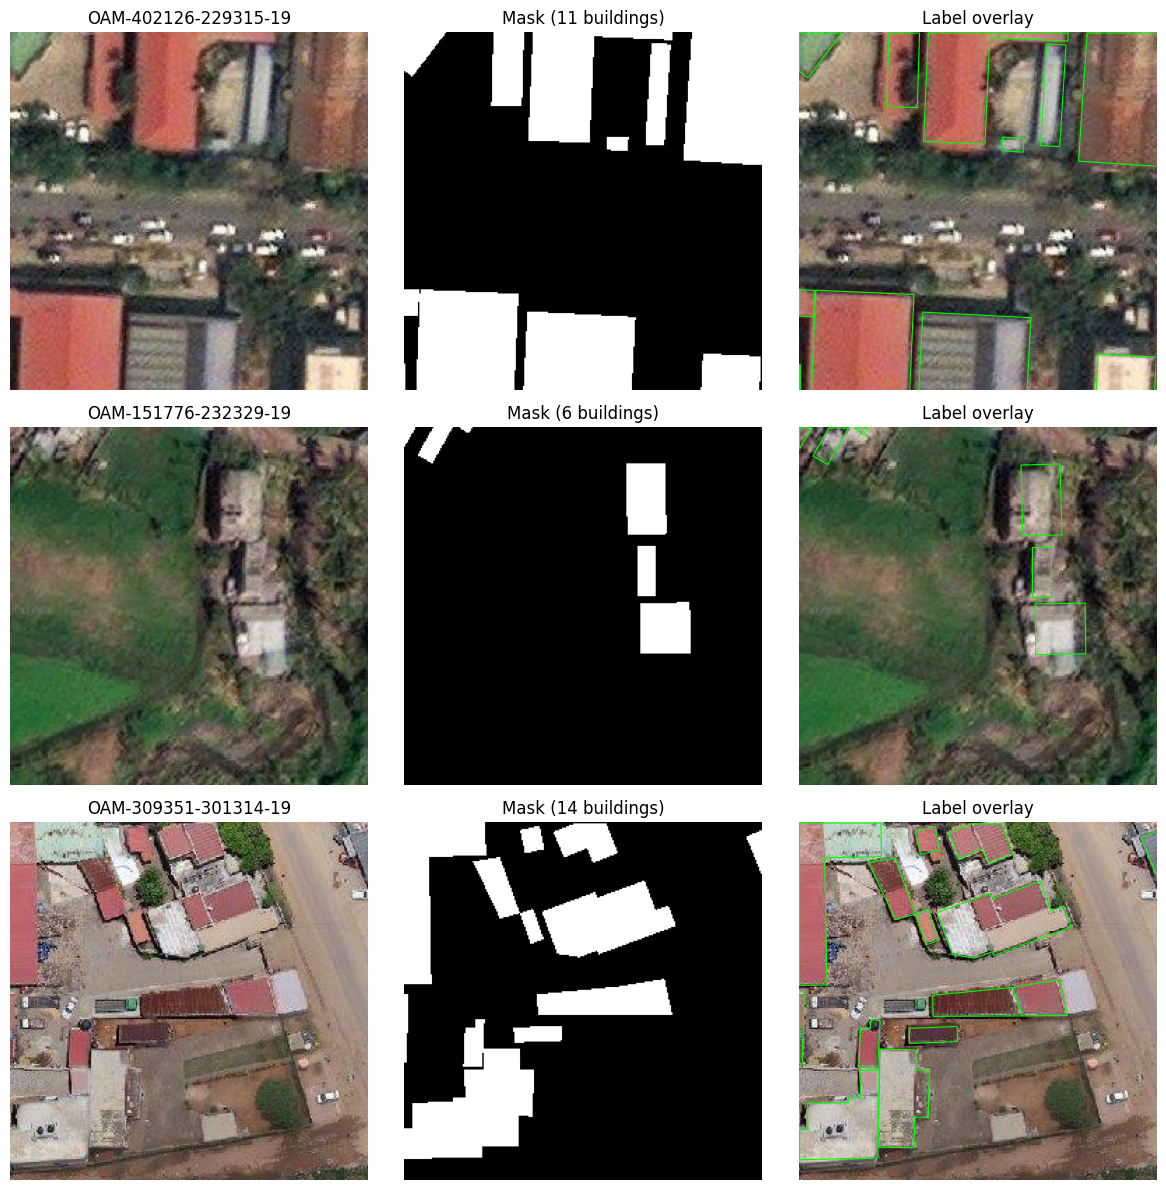

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon as MplPolygon
from shapely.geometry import shape


def show_sample(sample, ax_row):
    image = np.array(sample["image"])
    mask = np.array(sample["mask"])
    label = json.loads(sample["label_geojson"])

    ax_row[0].imshow(image)
    ax_row[0].set_title(f"{sample['tile_id']}")
    ax_row[0].axis("off")

    ax_row[1].imshow(mask, cmap="gray")
    ax_row[1].set_title(f"Mask ({sample['num_buildings']} buildings)")
    ax_row[1].axis("off")

    ax_row[2].imshow(image)
    for feat in label.get("features", []):
        geom = shape(feat["geometry"])
        if geom.geom_type == "Polygon":
            coords = np.array(geom.exterior.coords)
            pixel_x = (
                (coords[:, 0] - sample["bbox_west"])
                / (sample["bbox_east"] - sample["bbox_west"])
                * 256
            )
            pixel_y = (
                1
                - (coords[:, 1] - sample["bbox_south"])
                / (sample["bbox_north"] - sample["bbox_south"])
            ) * 256
            ax_row[2].add_patch(
                MplPolygon(
                    np.column_stack([pixel_x, pixel_y]), fill=False, edgecolor="lime", linewidth=0.8
                )
            )
    ax_row[2].set_title("Label overlay")
    ax_row[2].axis("off")


samples_with_buildings = ds.filter(lambda x: x["num_buildings"] > 5).shuffle().select(range(3))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    show_sample(samples_with_buildings[i], axes[i])
fig.tight_layout()
plt.show()

## Dataset Statistics

In [4]:
import pandas as pd

df = ds.to_pandas()
df = df.drop(columns=["image", "mask", "label_geojson"])

print(f"Countries: {df['country'].nunique()}")
print(f"Projects:  {df['project_id'].nunique()}")
print(f"Tiles:     {len(df):,}")
print(f"Buildings: {df['num_buildings'].sum():,}")
print()
df["country"].value_counts().to_frame("tiles")

Countries: 21
Projects:  93
Tiles:     72,363
Buildings: 715,775



,tiles
country,
Myanmar,43879
Peru,6778
Mozambique,4992
Eswatini,4983
Mexico,2753
Japan,1420
Sierra Leone,1306
Philippines,1203
Tajikistan,1150


## Geographic Coverage

In [5]:
import folium
from folium.plugins import MarkerCluster

centroids = df.groupby("project_id").agg(
    lat=pd.NamedAgg(column="bbox_south", aggfunc="mean"),
    lon=pd.NamedAgg(column="bbox_west", aggfunc="mean"),
    country=pd.NamedAgg(column="country", aggfunc="first"),
    tiles=pd.NamedAgg(column="tile_id", aggfunc="count"),
)

m = folium.Map(location=[10, 20], zoom_start=2, tiles="CartoDB positron")

marker_cluster = MarkerCluster().add_to(m)

for idx, row in centroids.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=min(20, max(5, row["tiles"] / 500)),  # Scale radius
        popup=f"Project: {idx}<br>Country: {row['country']}<br>Tiles: {row['tiles']}",
        color="crimson",
        fill=True,
        fill_color="crimson",
        fill_opacity=0.7,
    ).add_to(marker_cluster)

m

## Quick Training Example (PyTorch)

Minimal example for feeding this dataset into a PyTorch `DataLoader`.

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision.transforms import v2

transform = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
    ]
)


def collate(batch):
    images = torch.stack([transform(b["image"].convert("RGB")) for b in batch])
    masks = torch.stack(
        [torch.tensor(np.array(b["mask"]), dtype=torch.float32).unsqueeze(0) / 255.0 for b in batch]
    )
    return images, masks


loader = DataLoader(ds, batch_size=8, shuffle=True, collate_fn=collate, num_workers=0)
images, masks = next(iter(loader))
print(f"Batch images: {images.shape}  masks: {masks.shape}")

Batch images: torch.Size([8, 3, 256, 256])  masks: torch.Size([8, 1, 256, 256])
